<a href="https://colab.research.google.com/github/sabrina-cortes/Metodos-Numericos-FIS1344-TAREAS/blob/main/Tarea_10_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Tarea 10.3: Ecuaciones de alto orden y estabilidad

Enunciado: Así como implementamos el método de Runge Kutta de orden 4 para resolver sistemas de ecuaciones diferenciales, implemente el método de Runge Kutta Fehlberg para esos sistemas de ecuaciones.

Note que para modificar el tamaño del paso es necesario exigir que todas las soluciones alcancen la tolerancia pedida.

Para probar su código, resuelva el siguiente problema de valor inicial:

$$
y_1'(t)
=
-4y_1-2y_2+\cos t+4\sin t,
$$

$$
y_2'(t)
=
3y_1+y_2-3\sin t,
$$

para $0\leq t\leq 2$ con condiciones iniciales

$$
y_1(0)=0,
\qquad
y_2(0)=-1.
$$

Las soluciones analíticas son

$$
u_1(t)
=
2e^{-t}-2e^{-2t}+\sin t,
$$

$$
u_2(t)
=
-3e^{-t}+2e^{-2t}.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def f(t, y):

    return np.array([
        -4*y[0] - 2*y[1] + np.cos(t) + 4*np.sin(t),
         3*y[0] + y[1] - 3*np.sin(t)
    ])

In [3]:
#Condiciones Iniciales
a = 0
b = 2

yo = np.array([0.0, -1.0])

In [4]:
class MinStep(Exception):
    pass

In [5]:
def rkfs(f, a, b, yo, tol, hmin, hmax):

    t = a
    w = yo.copy()
    h = hmax
    flag = 1

    ts = [t]
    sol = [w.copy()]
    hs = []
    rs = []

    while flag:

        #Evaluaciones de la función
        k1 = h*f(t, w)

        k2 = h*f(
            t + h/4,
            w + k1/4
        )

        k3 = h*f(
            t + 3*h/8,
            w + 3*k1/32 + 9*k2/32
        )

        k4 = h*f(
            t + 12*h/13,
            w + 1932*k1/2197
              - 7200*k2/2197
              + 7296*k3/2197
        )

        k5 = h*f(
            t + h,
            w + 439*k1/216
              - 8*k2
              + 3680*k3/513
              - 845*k4/4104
        )

        k6 = h*f(
            t + h/2,
            w - 8*k1/27
              + 2*k2
              - 3544*k3/2565
              + 1859*k4/4104
              - 11*k5/40
        )

        #Modificamos rkf
        R = np.abs(
            k1/360
            - 128*k3/4275
            - 2197*k4/75240
            + k5/50
            + 2*k6/55
        )

        Rmax = np.max(R)

        #Se acepta solo si TODAS cumplen la tolerancia
        if np.all(R <= tol):

            t += h

            w = (
                w
                + 25*k1/216
                + 1408*k3/2565
                + 2197*k4/4104
                - k5/5
            )

            ts.append(t)
            sol.append(w.copy())
            hs.append(h)
            rs.append(R.copy())

        #Actualización del paso
        if Rmax == 0:
            q = 4
        else:
            q = 0.84*(tol/Rmax)**(1/4)

        if q <= 0.1:
            h = 0.1*h

        elif q >= 4:
            h = 4*h

        else:
            h = q*h

        if h > hmax:
            h = hmax

        if t >= b:
            flag = 0

        elif t + h > b:
            h = b - t

        elif h < hmin:
            raise MinStep("Se excedió el paso mínimo.")

    return (
        np.array(ts),
        np.array(sol),
        np.array(hs),
        np.array(rs)
    )

Ahora buscamos resolver el sistema. Podemos utilizar los mismos datos que se usó en la clase

In [6]:
tol = 1e-6
hmin = 0.001
hmax = 0.25

ts, sol, hs, rs = rkfs(
    f, a, b, yo,
    tol, hmin, hmax
)

Las soluciones analíticas entregadas en el enunciado son

$$
u_1(t)
=
2e^{-t}
-
2e^{-2t}
+
\sin t,
$$

y

$$
u_2(t)
=
-3e^{-t}
+
2e^{-2t}.
$$

In [7]:
def u1(t):
    return 2*np.exp(-t) - 2*np.exp(-2*t) + np.sin(t)

def u2(t):
    return -3*np.exp(-t) + 2*np.exp(-2*t)

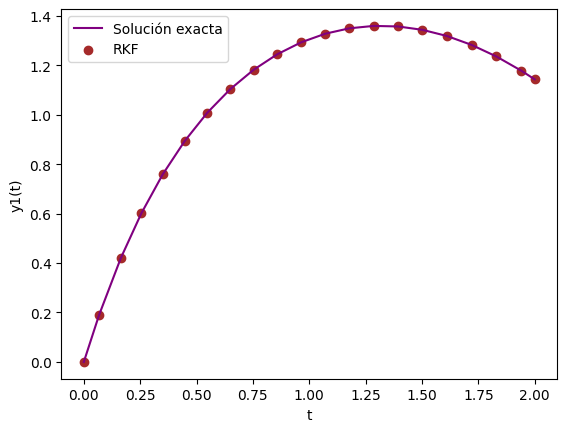

In [8]:
#Graficamos y_1
plt.plot(ts, u1(ts), color='purple' ,label="Solución exacta")
plt.scatter(ts, sol[:, 0], color='brown' ,label="RKF")

plt.xlabel("t")
plt.ylabel("y1(t)")
plt.legend()
plt.show()

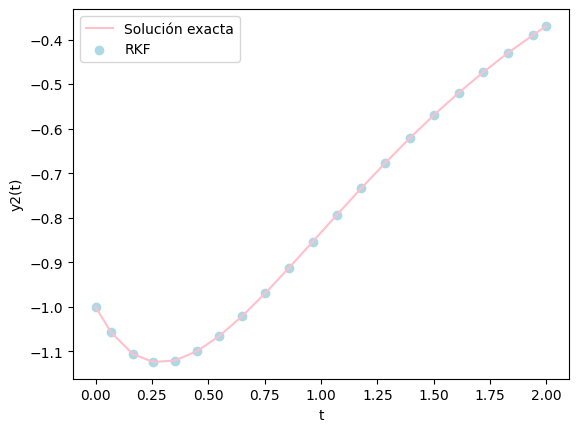

In [9]:
#Graficamos y_2
plt.plot(ts, u2(ts), color='pink' ,label="Solución exacta")
plt.scatter(ts, sol[:, 1], color='lightblue' ,label="RKF")

plt.xlabel("t")
plt.ylabel("y2(t)")
plt.legend()
plt.show()

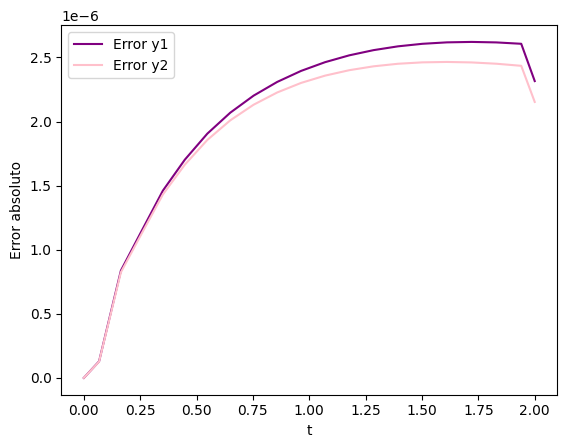

Error máximo y1 = 2.6212860979590857e-06
Error máximo y2 = 2.4650681771376526e-06


In [10]:
#Calculamos los errores
error1 = np.abs(sol[:, 0] - u1(ts))
error2 = np.abs(sol[:, 1] - u2(ts))

plt.plot(ts, error1, color='purple' ,label="Error y1")
plt.plot(ts, error2, color='pink' ,label="Error y2")

plt.xlabel("t")
plt.ylabel("Error absoluto")
plt.legend()
plt.show()

print("Error máximo y1 =", np.max(error1))
print("Error máximo y2 =", np.max(error2))

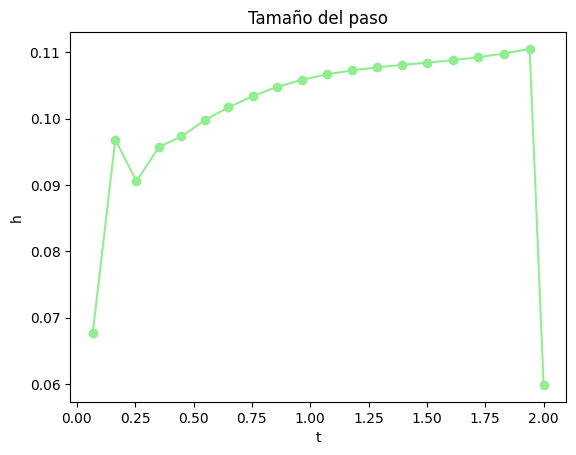

In [11]:
plt.plot(ts[1:], hs, color='lightgreen' ,marker="o")

plt.xlabel("t")
plt.ylabel("h")
plt.title("Tamaño del paso")
plt.show()

## Análisis

El método de Runge-Kutta-Fehlberg fue modificado para trabajar con un vector de soluciones,

$$
\mathbf{y}(t)=
\begin{pmatrix}
y_1(t)\\
y_2(t)
\end{pmatrix}.
$$

Por esta razón, los valores $k_1,\ldots,k_6$ y la estimación del error $R$ también son vectores.

Para aceptar un paso se exige que ambas componentes satisfagan la tolerancia:

$$
R_1\leq\mathrm{tol},
\qquad
R_2\leq\mathrm{tol}.
$$

Para modificar el tamaño del paso se utiliza el mayor error,

$$
R_{\max}=\max(R_1,R_2),
$$

de manera que el paso escogido permita controlar simultáneamente el error de ambas soluciones.

Al comparar los resultados numéricos con las soluciones analíticas, se puede comprobar la precisión del método para las dos ecuaciones del sistema.